In [6]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df = pd.read_csv(r"D:\data analytics files for practice\projects\amazon\amazon.csv")

In [44]:
df.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   product_id           1465 non-null   str  
 1   product_name         1465 non-null   str  
 2   category             1465 non-null   str  
 3   discounted_price     1465 non-null   str  
 4   actual_price         1465 non-null   str  
 5   discount_percentage  1465 non-null   str  
 6   rating               1465 non-null   str  
 7   rating_count         1463 non-null   str  
 8   about_product        1465 non-null   str  
 9   user_id              1465 non-null   str  
 10  user_name            1465 non-null   str  
 11  review_id            1465 non-null   str  
 12  review_title         1465 non-null   str  
 13  review_content       1465 non-null   str  
 14  img_link             1465 non-null   str  
 15  product_link         1465 non-null   str  
dtypes: str(16)
memory usage: 4.7 MB


In [22]:
df.shape

(1465, 16)

In [28]:
# Price columns: ₹ aur comma hatao, phir number banao
for col in ["discounted_price", "actual_price"]:
    df[col] = (df[col].str.replace("₹", "", regex=False)
                  .str.replace(",", "", regex=False))
    df[col] = pd.to_numeric(df[col], errors="coerce")          

In [30]:
# Discount: % hatao
df["discount_percentage"] = pd.to_numeric(df["discount_percentage"].str.replace("%", "", regex=False), errors="coerce")

In [31]:
# rating_count: comma hatao
df["rating_count"] = pd.to_numeric(df["rating_count"].str.replace(",", "", regex=False), errors="coerce")

In [32]:
# rating: kharab value (jaise "|") NaN ban jayegi
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   str    
 1   product_name         1465 non-null   str    
 2   category             1465 non-null   str    
 3   discounted_price     1465 non-null   float64
 4   actual_price         1465 non-null   float64
 5   discount_percentage  1465 non-null   int64  
 6   rating               1464 non-null   float64
 7   rating_count         1463 non-null   float64
 8   about_product        1465 non-null   str    
 9   user_id              1465 non-null   str    
 10  user_name            1465 non-null   str    
 11  review_id            1465 non-null   str    
 12  review_title         1465 non-null   str    
 13  review_content       1465 non-null   str    
 14  img_link             1465 non-null   str    
 15  product_link         1465 non-null   str    
dtyp

In [34]:
print(df.isnull().sum())
print("Duplicate products:", df.duplicated(subset="product_id").sum())

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64
Duplicate products: 114


In [35]:
df = df.dropna(subset=["rating", "rating_count"])
df = df.drop_duplicates(subset="product_id").reset_index(drop=True)
print(df.shape)

(1348, 16)


In [36]:
df["main_category"] = df["category"].str.split("|").str[0]
print(df["main_category"].value_counts())

main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


In [37]:
summary = (df.groupby("main_category")
             .agg(products=("product_id", "count"),
                  avg_discount=("discount_percentage", "mean"),
                  avg_rating=("rating", "mean"),
                  total_rating_count=("rating_count", "sum"))
             .round(2)
             .sort_values("total_rating_count", ascending=False))
print(summary)

                       products  avg_discount  avg_rating  total_rating_count
main_category                                                                
Electronics                 490         49.91        4.08          14208406.0
Computers&Accessories       373         53.09        4.15           6335177.0
Home&Kitchen                447         40.17        4.04           2990077.0
OfficeProducts               31         12.35        4.31            149675.0
MusicalInstruments            2         46.00        3.90             88882.0
Toys&Games                    1          0.00        4.30             15867.0
HomeImprovement               2         57.50        4.25              8566.0
Health&PersonalCare           1         53.00        4.00              3663.0
Car&Motorbike                 1         42.00        3.80              1118.0


In [38]:
df["discount_bucket"] = pd.cut(df["discount_percentage"],
                               bins=[0, 20, 40, 60, 80, 100],
                               labels=["0-20", "21-40", "41-60", "61-80", "81-100"],
                               include_lowest=True)

p1 = df.groupby("discount_bucket", observed=True).agg(
        products=("product_id", "count"),
        median_rating_count=("rating_count", "median"),
        avg_rating=("rating", "mean")).round(2)
print(p1)

print(df[["discount_percentage", "rating_count"]].corr(method="spearman"))

                 products  median_rating_count  avg_rating
discount_bucket                                           
0-20                  175               6736.0        4.17
21-40                 329               7241.0        4.13
41-60                 469               3025.0        4.07
61-80                 324               4147.0        4.07
81-100                 51               4426.0        3.97
                     discount_percentage  rating_count
discount_percentage             1.000000     -0.132227
rating_count                   -0.132227      1.000000


In [39]:
high_demand = df["rating_count"].quantile(0.75)
risky = df[(df["rating"] < 3.8) & (df["rating_count"] >= high_demand)]
print(risky[["product_name", "main_category", "rating", "rating_count", "discount_percentage"]]
      .sort_values("rating_count", ascending=False).head(10))

                                          product_name          main_category  \
649  JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...            Electronics   
407  PTron Tangent Lite Bluetooth 5.0 Earphones wit...            Electronics   
614  Zebronics ZEB-KM2100 Multimedia USB Keyboard C...  Computers&Accessories   
598  Boult Audio AirBass PowerBuds with Inbuilt Pow...            Electronics   
704  Boult Audio Truebuds with 30H Playtime, IPX7 W...            Electronics   
564  ZEBRONICS Zeb-Bro in Ear Wired Earphones with ...            Electronics   
785  HP Deskjet 2331 Colour Printer, Scanner and Co...  Computers&Accessories   
400  PTron Boom Ultima 4D Dual Driver, in-Ear Gamin...            Electronics   

     rating  rating_count  discount_percentage  
649     3.7       87798.0                   50  
407     3.5       83996.0                   67  
614     3.6       33735.0                   18  
598     3.7       28324.0                   83  
704     3.6       25910.0

In [40]:
df["cat_avg_price"] = df.groupby("main_category")["discounted_price"].transform("mean")
df["price_vs_cat"] = df["discounted_price"] / df["cat_avg_price"]

overpriced = df[(df["price_vs_cat"] > 1.5) & (df["rating"] < 4.0)]
print(overpriced[["product_name", "main_category", "discounted_price",
                  "cat_avg_price", "rating"]].head(10))

                                          product_name          main_category  \
157  EGate i9 Pro-Max 1080p Native Full HD Projecto...            Electronics   
307  Sansui 80cm (32 inches) HD Ready Smart LED TV ...            Electronics   
324  AmazonBasics 108 cm (43 inches) 4K Ultra HD Sm...            Electronics   
382  Redmi Note 11 Pro + 5G (Stealth Black, 6GB RAM...            Electronics   
417  Redmi Note 11 Pro + 5G (Phantom White, 8GB RAM...            Electronics   
424  Redmi Note 11 Pro + 5G (Stealth Black, 8GB RAM...            Electronics   
470  Redmi 11 Prime 5G (Meadow Green, 4GB RAM 64GB ...            Electronics   
498  Redmi 11 Prime 5G (Thunder Black, 4GB RAM, 64G...            Electronics   
518  Samsung Galaxy M53 5G (Deep Ocean Blue, 6GB, 1...            Electronics   
701  APC Back-UPS BX600C-IN 600VA / 360W, 230V, UPS...  Computers&Accessories   

     discounted_price  cat_avg_price  rating  
157            9490.0    6225.869388     3.9  
307           

In [41]:
low_demand = df["rating_count"].quantile(0.25)
gems = df[(df["rating"] >= 4.3) & (df["rating_count"] <= low_demand)]
print(gems[["product_name", "main_category", "rating", "rating_count",
            "discount_percentage"]].sort_values("rating", ascending=False).head(10))

                                           product_name  \
174   Syncwire LTG to USB Cable for Fast Charging Co...   
699   Amazon Basics Wireless Mouse | 2.4 GHz Connect...   
1085  Oratech Coffee Frother electric, milk frother ...   
1110  Zuvexa USB Rechargeable Electric Foam Maker - ...   
1172  Aquadpure Copper + Mineral RO+UV+UF 10 to 12 L...   
542   WeCool S5 Long Selfie Stick, with Large Reinfo...   
1176  Melbon VM-905 2000-Watt Room Heater (ISI Certi...   
1003  Lint Remover Woolen Clothes Lint Extractor Bat...   
1100  VRPRIME Lint Roller Lint Remover for Clothes, ...   
20    Duracell USB Lightning Apple Certified (Mfi) B...   

              main_category  rating  rating_count  discount_percentage  
174   Computers&Accessories     5.0           5.0                   80  
699   Computers&Accessories     5.0          23.0                   50  
1085           Home&Kitchen     4.8          28.0                   44  
1110           Home&Kitchen     4.7          54.0         

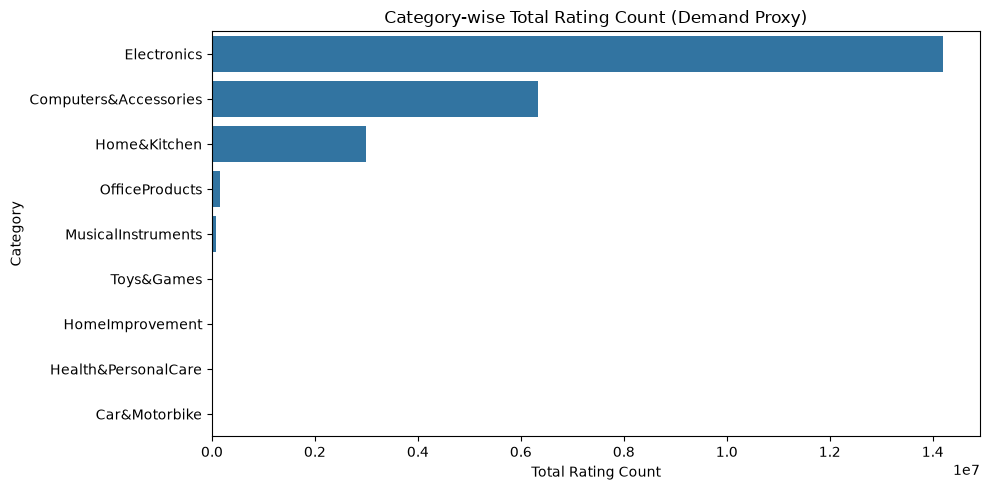

In [42]:
plt.figure(figsize=(10, 5))
sns.barplot(x=summary["total_rating_count"], y=summary.index)
plt.title("Category-wise Total Rating Count (Demand Proxy)")
plt.xlabel("Total Rating Count")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("category_demand.png", dpi=150)
plt.show()